# 02 — Descarga, carga y revisión de calidad de los datos

**Objetivo:** traer el dataset Prosper desde Kaggle, cargarlo sin modificarlo, documentar sus variables y medir su calidad.

**Resultados que guarda:**
- `data/interim/prosper_crudo.parquet`: datos con fechas ya tipadas (los usa el notebook 03)
- `docs/diccionario_variables.csv`: diccionario técnico de las columnas
- `docs/calidad_resumen.csv`: indicadores de calidad
- `docs/figuras/02_nulos_top25.png`: gráfica de valores faltantes

## 1. Preparar rutas e importaciones

In [11]:
import sys
from pathlib import Path

RAIZ = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

import pandas as pd
import matplotlib.pyplot as plt

from src.config import RUTAS, crear_carpetas
from src.datos import (descargar_prosper, buscar_csv_crudo, cargar_crudo,
                       perfil_columnas, resumen_calidad, COLUMNAS_FUGA)

crear_carpetas()
pd.set_option('display.max_columns', 100)
pd.set_option('display.max_rows', 120)

## 2. Descargar el dataset (solo la primera vez)
Si el CSV ya está en `data/raw/`, no se vuelve a descargar. Si falla la descarga automática, usa la opción manual de `data/README.md` y vuelve a ejecutar.

In [12]:
if list(RUTAS['data_raw'].glob('*.csv')):
    print('El CSV ya existe en data/raw/, no se descarga de nuevo.')
else:
    archivos = descargar_prosper()
    print('Descargado:', [a.name for a in archivos])

ruta_csv = buscar_csv_crudo()
print('Archivo a usar:', ruta_csv.name, f'({ruta_csv.stat().st_size / 1024**2:.1f} MB)')

El CSV ya existe en data/raw/, no se descarga de nuevo.
Archivo a usar: prosperLoanData.csv (82.5 MB)


## 3. Cargar y verificar dimensiones
El enunciado habla de ~114.000 filas y 81 columnas: aquí lo **verificamos** en lugar de suponerlo.

In [13]:
df = cargar_crudo(ruta_csv)
print(f'Filas: {df.shape[0]:,}  |  Columnas: {df.shape[1]}')
df.head(3).T  # transpuesto: una fila por columna, más fácil de leer con 81 columnas

Filas: 113,937  |  Columnas: 81


,0,1,2
ListingKey,1021339766868145413AB3B,10273602499503308B223C1,0EE9337825851032864889A
ListingNumber,193129,1209647,81716
ListingCreationDate,2007-08-26 19:09:29.263000,2014-02-27 08:28:07.900000,2007-01-05 15:00:47.090000
CreditGrade,C,NaN,HR
Term,36,36,36
LoanStatus,Completed,Current,Completed
ClosedDate,2009-08-14 00:00:00,NaT,2009-12-17 00:00:00
BorrowerAPR,0.16516,0.12016,0.28269
BorrowerRate,0.158,0.092,0.275
LenderYield,0.138,0.082,0.24


## 4. Tipos de datos (`df.info()`)
📋 **Pega esta salida en el chat**: con ella se arma el diccionario de negocio y se decide el rol de cada variable.

In [14]:
df.info(verbose=True, show_counts=True)

<class 'pandas.DataFrame'>
RangeIndex: 113937 entries, 0 to 113936
Data columns (total 81 columns):
 #   Column                               Non-Null Count   Dtype         
---  ------                               --------------   -----         
 0   ListingKey                           113937 non-null  str           
 1   ListingNumber                        113937 non-null  int64         
 2   ListingCreationDate                  113937 non-null  datetime64[ns]
 3   CreditGrade                          28953 non-null   str           
 4   Term                                 113937 non-null  int64         
 5   LoanStatus                           113937 non-null  str           
 6   ClosedDate                           55089 non-null   datetime64[ns]
 7   BorrowerAPR                          113912 non-null  float64       
 8   BorrowerRate                         113937 non-null  float64       
 9   LenderYield                          113937 non-null  float64       
 10  Estimat

## 5. Resumen de calidad

In [15]:
calidad = resumen_calidad(df)
calidad

,indicador,valor
0,filas,113937.0
1,columnas,81.0
2,filas_duplicadas_exactas,0.0
3,columnas_100pct_nulas,0.0
4,columnas_constantes,0.0
5,columnas_con_mas_50pct_nulos,12.0
6,memoria_mb,83.6
7,duplicados_en_ListingKey,871.0
8,duplicados_en_GroupKey,113230.0
9,duplicados_en_LoanKey,871.0


## 6. Valores faltantes por columna
Las columnas con muchos nulos no se descartan automáticamente: en Prosper, varias variables solo existen para créditos de cierto periodo, y el nulo puede tener significado.

Columnas con al menos un nulo: 43


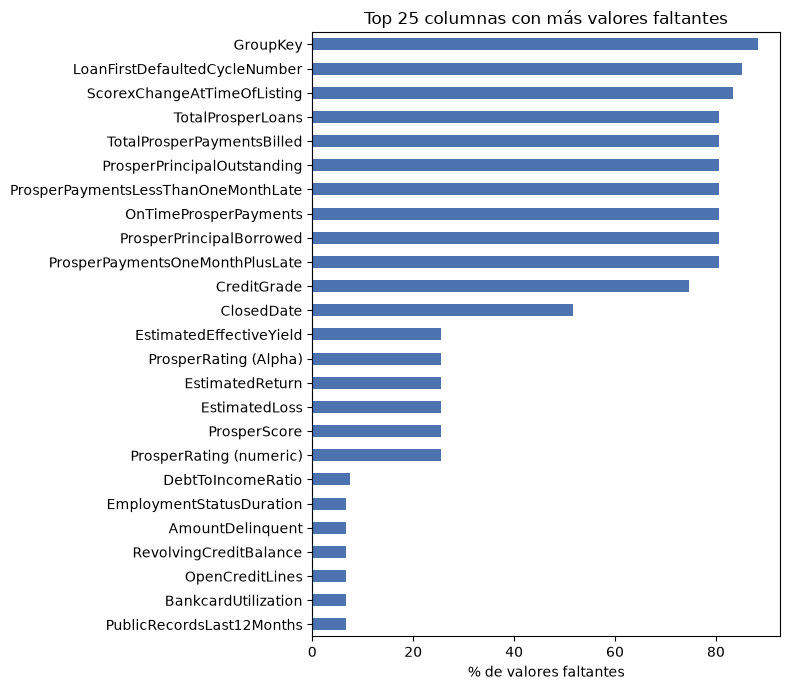

,pct_nulos
GroupKey,88.29
LoanFirstDefaultedCycleNumber,85.12
ScorexChangeAtTimeOfListing,83.39
ProsperPaymentsOneMonthPlusLate,80.62
TotalProsperLoans,80.62
ProsperPaymentsLessThanOneMonthLate,80.62
ProsperPrincipalBorrowed,80.62
TotalProsperPaymentsBilled,80.62
OnTimeProsperPayments,80.62
ProsperPrincipalOutstanding,80.62


In [16]:
nulos = (df.isna().mean() * 100).sort_values(ascending=False)
print('Columnas con al menos un nulo:', (nulos > 0).sum())

top = nulos.head(25).sort_values()
fig, ax = plt.subplots(figsize=(8, 7))
top.plot.barh(ax=ax, color='#4C72B0')
ax.set_xlabel('% de valores faltantes')
ax.set_title('Top 25 columnas con más valores faltantes')
plt.tight_layout()
fig.savefig(RUTAS['figuras'] / '02_nulos_top25.png', dpi=150)
plt.show()

nulos[nulos > 0].round(2).to_frame('pct_nulos')

## 7. Estado del crédito (`LoanStatus`)
De aquí sale la **población objetivo** del proyecto (Chargedoff y Defaulted).

In [17]:
estado = df['LoanStatus'].value_counts(dropna=False).to_frame('creditos')
estado['pct'] = (estado['creditos'] / len(df) * 100).round(2)
estado

,creditos,pct
LoanStatus,,
Current,56576,49.66
Completed,38074,33.42
Chargedoff,11992,10.53
Defaulted,5018,4.40
Past Due (1-15 days),806,0.71
Past Due (31-60 days),363,0.32
Past Due (61-90 days),313,0.27
Past Due (91-120 days),304,0.27
Past Due (16-30 days),265,0.23


## 8. Rango de fechas
Necesario para la **validación temporal** (entrenar con créditos antiguos y validar con recientes).

In [18]:
cols_fecha = df.select_dtypes(include='datetime').columns
pd.DataFrame({
    'minima': df[cols_fecha].min(),
    'maxima': df[cols_fecha].max(),
    'pct_nulos': (df[cols_fecha].isna().mean() * 100).round(2),
})

,minima,maxima,pct_nulos
ListingCreationDate,2005-11-09 20:44:28.847,2014-03-10 12:20:53.760,0.00
ClosedDate,2005-11-25 00:00:00.000,2014-03-10 00:00:00.000,51.65
DateCreditPulled,2005-11-09 00:30:04.487,2014-03-10 12:20:56.000,0.00
LoanOriginationDate,2005-11-15 00:00:00.000,2014-03-12 00:00:00.000,0.00


## 9. Verificar las columnas de fuga de datos
Confirmamos que existen con esos nombres exactos. Se usarán **solo** para construir la variable objetivo y el ROI.

In [19]:
for col in COLUMNAS_FUGA:
    print(f"{'✅' if col in df.columns else '❌ NO EXISTE'}  {col}")

✅  ClosedDate
✅  LP_CustomerPayments
✅  LP_CustomerPrincipalPayments
✅  LP_InterestandFees
✅  LP_ServiceFees
✅  LP_CollectionFees
✅  LP_GrossPrincipalLoss
✅  LP_NetPrincipalLoss
✅  LP_NonPrincipalRecoverypayments
✅  LoanCurrentDaysDelinquent
✅  LoanMonthsSinceOrigination


## 10. Guardar resultados
El notebook 03 leerá el parquet: es más rápido que el CSV y conserva los tipos de fecha.

In [20]:
diccionario = perfil_columnas(df)
diccionario.to_csv(RUTAS['docs'] / 'diccionario_variables.csv', index=False, encoding='utf-8-sig')
calidad.to_csv(RUTAS['docs'] / 'calidad_resumen.csv', index=False, encoding='utf-8-sig')

salida = RUTAS['data_interim'] / 'prosper_crudo.parquet'
df.to_parquet(salida, index=False)

print('✅ Guardado:')
print('  ', salida.relative_to(RUTAS['raiz']), f'({salida.stat().st_size / 1024**2:.1f} MB)')
print('   docs/diccionario_variables.csv')
print('   docs/calidad_resumen.csv')
print('   docs/figuras/02_nulos_top25.png')

✅ Guardado:
   data\interim\prosper_crudo.parquet (19.7 MB)
   docs/diccionario_variables.csv
   docs/calidad_resumen.csv
   docs/figuras/02_nulos_top25.png
